# Génération de 4 ans de capteurs SYNTHÉTIQUES (4 machines, 1 minute)

> ⚠️ **Toutes les données produites ici sont inventées.** Elles servent à tester une démarche (JEPA contre baselines) sur une vérité terrain connue. Elles ne prouvent rien sur une machine réelle.

**Objectif.** Produire des capteurs où les pannes et les ralentissements **ne se lisent pas directement** dans le niveau d'un capteur :
- aucune panne ne fait monter « la » température ou « la » vibration au-dessus d'un seuil ;
- une dégradation change la **dynamique** ou la **relation entre capteurs** (constante de temps thermique, réponse vibratoire selon la vitesse, retard courant/vitesse, fréquence de cyclage du compresseur), en gardant les niveaux moyens presque inchangés ;
- les grandes variations de niveau viennent d'événements **bénins** (saisons, canicules, recalibrages de capteurs, changements de produit, vieillissement annuel), qui piègent les seuils et les EWMA.

C'est un cas **favorable par construction** à un modèle qui apprend la dynamique normale (JEPA), et défavorable aux seuils. Le notebook d'analyse vérifie si JEPA en profite vraiment, face à des baselines honnêtes (dont un boosting avec des caractéristiques de dynamique).

**Période** : 01/09/2022 → 31/08/2026, une ligne par minute et par machine (2 103 840 lignes par machine).

**Sorties** (dossier `input/capteurs_4ans/`) :
- `capteurs_<machine>_<année>.csv.gz` : entrée des modèles (un fichier par machine et par année d'exploitation sept. → août) ;
- `verite_terrain_degradations.csv` : chaque dégradation (début, type, issue, instant de panne ou de maintenance) — **évaluation uniquement** ;
- `verite_terrain_benins.csv` : canicules, recalibrages, capteurs figés, pertes de données — **évaluation uniquement** ;
- `config_generation.json`, `controle_visuel.png` ;
- `flotte_non_etiquetee/` : 12 machines de plus (M5 à M16), pour le pré-entraînement sans étiquettes (section 8).

In [1]:
import os, json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import lfilter

OUT = Path(os.environ.get("FJEPA_OUT", "../input/capteurs_4ans"))
OUT.mkdir(parents=True, exist_ok=True)
SEED = 2026
T0, T1 = pd.Timestamp("2022-09-01 00:00"), pd.Timestamp("2026-09-01 00:00")
IDX = pd.date_range(T0, T1, freq="1min", inclusive="left")
N = len(IDX)
print(N, "minutes par machine")

2103840 minutes par machine


## 1. Paramètres

Les ordres de grandeur sont des hypothèses plausibles pour un petit équipement agroalimentaire (moteur de quelques kW, réseau pneumatique à 6 bar). **Ils ne sont pas mesurés.**

| Type de dégradation | Ce qui change | Ce qui ne change (presque) pas |
|---|---|---|
| `refroidissement` (ventilation encrassée) | constante de temps thermique du moteur ×1 → ×2,5 : la température suit la charge plus lentement | température moyenne, niveau en régime établi |
| `roulement` | la résonance vibratoire glisse vers les basses vitesses et s'élargit ; le bruit vibratoire devient plus corrélé dans le temps | vibration moyenne sur la plage de vitesses habituelle |
| `courroie` (glissement) | le courant suit la vitesse avec retard, oscillation lente, micro-glissements simultanés courant ↓ / vibration ↑ | moyenne et variance du courant |
| `pneumatique` (fuite) | le compresseur cycle plus vite (période 8 → 3,5 min), la pression chute plus vite à l'arrêt | pression moyenne et amplitude en production |
| `electrique` (brutal) | pic de courant dans les 10 dernières minutes | **imprévisible** à 7 jours, gardé pour l'honnêteté du test |

Chaque dégradation a une sévérité qui croît de 0 à 1 (forme tirée au hasard) ; les dégradations `courroie` et `pneumatique` sont **intermittentes** (épisodes on/off). Issue : **panne** (arrêt de réparation 2 à 10 h), **ralentissement** (l'équipe réduit la cadence à 55–75 % pendant 4 à 24 h de production, puis intervient), ou **maintenance préventive** (dégradation interrompue à 50–85 %, sans panne : cas censuré).

In [2]:
MACHINES = {
    "M1": dict(nom="Mouleuse", i0=4.5, k_i=7.5, tau_m=35, tau_b=70, v0=1.1, s_res=1.05, p0=6.0),
    "M2": dict(nom="Démouleuse", i0=3.8, k_i=6.2, tau_m=30, tau_b=60, v0=1.4, s_res=0.95, p0=6.2),
    "M3": dict(nom="Trancheuse", i0=5.2, k_i=9.0, tau_m=42, tau_b=80, v0=0.9, s_res=1.10, p0=5.8),
    "M4": dict(nom="Conditionneuse", i0=2.9, k_i=5.1, tau_m=28, tau_b=55, v0=1.7, s_res=1.00, p0=6.0),
}
FAULT_TYPES = {  # proba, durée du précurseur (jours), intermittent
    "refroidissement": (0.24, (5, 18), False),
    "roulement":       (0.24, (6, 21), False),
    "courroie":        (0.20, (3, 12), True),
    "pneumatique":     (0.20, (3, 12), True),
    "electrique":      (0.12, (0, 0), False),
}
GAP_DAYS = (12, 40)          # durée saine entre la fin d'une intervention et le début de la dégradation suivante
OUTCOME_P = {"panne": 0.55, "ralentissement": 0.25, "preventif": 0.20}
N_PRODUCTS = 12
CFG = dict(seed=SEED, machines=MACHINES, fault_types={k: [v[0], list(v[1]), v[2]] for k, v in FAULT_TYPES.items()},
           gap_days=GAP_DAYS, outcome_p=OUTCOME_P, n_products=N_PRODUCTS)

def ar1(n, phi, rng):
    x = lfilter([1.0], [1.0, -phi], rng.standard_normal(n))
    return x / x.std()

def first_order(target, tau, x0=None):
    # filtre du premier ordre à constante de temps variable (minutes) : x[k] = a x[k-1] + (1-a) u[k]
    a = np.exp(-1.0 / np.asarray(tau, float))
    if a.ndim == 0:
        return lfilter([1 - a], [1, -a], target, zi=[a * (target[0] if x0 is None else x0)])[0]
    out = []; x = target[0] if x0 is None else x0
    for ak, uk in zip(a.tolist(), np.asarray(target, float).tolist()):
        x = ak * x + (1 - ak) * uk; out.append(x)
    return np.array(out)

## 2. Planning de production (inventé, inspiré des ordres de grandeur réels)

Lundi–vendredi 05:00–21:00 (95 % des jours), samedi matin un sur trois, dimanche fermé, fermeture du 1er au 21 août et entre Noël et le Nouvel An. Dans les heures ouvertes : campagnes produit de 2 à 12 h, changements de produit de 20 à 45 min, micro-arrêts (≈ 0,6 par heure, 1 à 6 min), ralentissements bénins de l'opérateur (−20 % pendant 30 à 120 min, sans lien avec une dégradation).

In [3]:
def build_schedule(rng):
    open_ = np.zeros(N, bool)
    days = pd.date_range(T0, T1, freq="D", inclusive="left")
    for i, d in enumerate(days):
        if (d.month == 8 and d.day <= 21) or (d.month == 12 and d.day >= 24) or (d.month == 1 and d.day == 1):
            continue
        wd = d.dayofweek
        if wd < 5 and rng.random() < 0.95:
            open_[i * 1440 + 300: i * 1440 + 1260] = True
        elif wd == 5 and rng.random() < 0.33:
            open_[i * 1440 + 300: i * 1440 + 780] = True
    prod_load = 0.85 + 0.35 * rng.random(N_PRODUCTS)
    prod_cad = 0.85 + 0.30 * rng.random(N_PRODUCTS)
    speed = np.zeros(N); product = np.full(N, -1, int)
    d = np.diff(np.r_[0, open_.astype(np.int8), 0])
    for k0, k1 in zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)):   # plages ouvertes
        k = int(k0)
        while k < k1:
            p = rng.integers(N_PRODUCTS); L = int(rng.uniform(120, 720))
            e = min(k + L, int(k1))
            seg = prod_cad[p] * (1 + 0.04 * ar1(e - k, 0.97, rng)) if e - k > 5 else np.full(e - k, prod_cad[p])
            speed[k:e] = seg; product[k:e] = p
            k = e + int(rng.uniform(20, 45))           # changement de produit : arrêt
    run = speed > 0
    # micro-arrêts et ralentissements bénins
    idx_run = np.flatnonzero(run)
    for s in rng.choice(idx_run, size=int(len(idx_run) / 60 * 0.6), replace=False):
        speed[s:s + int(rng.integers(1, 7))] = 0
    for s in rng.choice(idx_run, size=int(len(idx_run) / 1440 * 0.5), replace=False):
        e = s + int(rng.uniform(30, 120)); speed[s:e] *= 0.8
    return open_, speed, product, prod_load

## 3. Dégradations, pannes et ralentissements

Les dégradations se succèdent sur chaque machine : période saine (12 à 40 jours après la dernière intervention), précurseur, puis issue. Le **type de dégradation est indépendant de la saison** (pour ne pas recréer le biais « chaud = panne » de la version précédente).

In [4]:
def place_faults(open_, speed, rng, mid):
    faults = []
    t = int(rng.uniform(5, 30) * 1440)
    types = list(FAULT_TYPES); probs = np.array([FAULT_TYPES[k][0] for k in types])
    outs = list(OUTCOME_P); pout = np.array(list(OUTCOME_P.values()))
    run = speed > 0
    while True:
        ftype = types[rng.choice(len(types), p=probs)]
        lo, hi = FAULT_TYPES[ftype][1]
        D = int(rng.uniform(lo, hi) * 1440) if hi > 0 else 10
        onset = t
        te = onset + D
        if te >= N - 3 * 1440: break
        nxt = np.flatnonzero(run[te:te + 10 * 1440])       # l'événement se produit en production
        if len(nxt) == 0: t = te + 1440; continue
        te = te + int(nxt[0])
        outcome = "panne" if ftype == "electrique" else outs[rng.choice(3, p=pout)]
        f = dict(machine=mid, type=ftype, onset=onset, event=te, outcome=outcome,
                 shape=float(rng.uniform(0.7, 2.5)), intermittent=FAULT_TYPES[ftype][2],
                 sev_end=1.0 if outcome != "preventif" else float(rng.uniform(0.5, 0.85)))
        if outcome == "panne":
            f["repair_start"] = te; f["repair_end"] = te + int(rng.uniform(2, 10) * 60)
        elif outcome == "ralentissement":
            # la cadence réduite dure 4 à 24 h de production, puis réparation de 1 à 3 h
            L = int(rng.uniform(4, 24) * 60); runs = np.flatnonzero(run[te:te + 20 * 1440])
            slow_end = te + int(runs[min(L, len(runs) - 1)])
            f["slow_end"] = slow_end; f["repair_start"] = slow_end; f["repair_end"] = slow_end + int(rng.uniform(1, 3) * 60)
        else:  # maintenance préventive pendant une fermeture ou en production : arrêt 1 à 2 h
            f["repair_start"] = te; f["repair_end"] = te + int(rng.uniform(1, 2) * 60)
        f["repair_end"] = min(f["repair_end"], N - 1)
        faults.append(f)
        t = f["repair_end"] + int(rng.uniform(*GAP_DAYS) * 1440)
        if t >= N: break
    return faults

def severity_arrays(faults, rng):
    sev = {k: np.zeros(N) for k in FAULT_TYPES}
    for f in faults:
        a, b = f["onset"], f["repair_start"]
        if f["type"] == "electrique":
            k = np.arange(f["event"] - 10, f["event"]); sev["electrique"][k] = np.linspace(0.1, 1, len(k)); continue
        k = np.arange(a, b)
        frac = np.clip((k - a) / max(f["event"] - a, 1), 0, 1)
        s = f["sev_end"] * frac ** f["shape"]
        if f["intermittent"]:
            # épisodes on/off de 1 à 8 h ; la probabilité d'être « on » croît avec l'avancement
            on = np.zeros(len(k)); j = 0
            while j < len(k):
                L = int(rng.uniform(60, 480)); on[j:j + L] = rng.random() < 0.25 + 0.75 * frac[j]; j += L
            s = s * on
        sev[f["type"]][k] = np.maximum(sev[f["type"]][k], s)
    return sev

## 4. Événements bénins (ne doivent pas déclencher d'alerte)

- **Canicules** : 2 à 3 par été, +4 à +8 °C d'ambiante pendant 3 à 9 jours (toutes machines, même atelier).
- **Recalibrages de capteurs** : tous les 30 à 90 jours et une fois sur deux après une réparation ; décalage de température moteur et palier (±1 à 3 °C), gain de vibration (×0,85 à ×1,2), décalage de courant (±0,2 à 0,6 A). Le décalage reste jusqu'au recalibrage suivant.
- **Vieillissement** : la vibration de fond monte d'environ 10 % par an, remise à zéro à la révision d'août.
- **Capteurs figés** (température moteur, 6 à 24 h), **pertes de données** (2 à 8 h, un capteur au hasard), **pics isolés** (≈ 1 par jour).

Ces événements font bouger les **niveaux** beaucoup plus que les dégradations.

In [5]:
def heatwaves(rng):
    hw = np.zeros(N); log = []
    for y in range(2023, 2027):
        for _ in range(int(rng.integers(2, 4))):
            d0 = pd.Timestamp(f"{y}-06-10") + pd.Timedelta(days=float(rng.uniform(0, 80)))
            L = float(rng.uniform(3, 9)); amp = float(rng.uniform(4, 8))
            a = int((d0 - T0).total_seconds() // 60); b = min(N, a + int(L * 1440))
            ramp = np.minimum(1, np.minimum(np.arange(b - a), np.arange(b - a)[::-1]) / 1440)
            hw[a:b] = np.maximum(hw[a:b], amp * ramp)
            log.append(dict(machine="toutes", type="canicule", debut=IDX[a], fin=IDX[b - 1], amplitude=round(amp, 1)))
    return hw, log

HW, HW_LOG = heatwaves(np.random.default_rng(SEED + 99))
DOY = IDX.dayofyear.to_numpy(); HOD = (IDX.hour + IDX.minute / 60).to_numpy()
TAMB_SHOP = 17 + 6 * np.sin(2 * np.pi * (DOY - 105) / 365.25) + 2.5 * np.sin(2 * np.pi * (HOD - 9) / 24) + HW

## 5. Modèle physique des capteurs

| Capteur | Modèle sain |
|---|---|
| `temp_ambiante_c` | atelier : saison + jour/nuit + canicules + bruit lent ; décalage propre à la machine |
| `courant_a` | à vide + gain × charge (vitesse × facteur produit), bruit AR(1) ; 0,8 A en veille |
| `temp_moteur_c` | premier ordre (τ = 28 à 42 min) vers ambiante + échauffement ∝ (I/I_nom)² |
| `temp_palier_c` | premier ordre lent (τ = 55 à 80 min) vers ambiante + échauffement ∝ vitesse^1,5 + couplage moteur |
| `vibration_mm_s` | RMS : base × (0,5 + 0,5·vitesse) × (1 + bosse de résonance), bruit log-normal ; fond 0,03 mm/s à l'arrêt |
| `pression_bar` | réseau régulé : dents de scie du compresseur (période 8 min) entre P0 ± 0,35 bar quand l'atelier est ouvert ; décroissance lente quand il est fermé |

In [6]:
def simulate_machine(mid, P, seed):
    rng = np.random.default_rng(seed)
    open_, speed, product, prod_load = build_schedule(rng)
    faults = place_faults(open_, speed, rng, mid)
    # appliquer les issues : arrêts de réparation et ralentissements
    for f in faults:
        if f["outcome"] == "ralentissement":
            speed[f["event"]:f["slow_end"]] *= rng.uniform(0.55, 0.75)
        speed[f["repair_start"]:f["repair_end"]] = 0
        open_[f["repair_start"]:f["repair_end"]] = True
    sev = severity_arrays(faults, rng)
    sR, sB, sC, sP, sE = (sev[k] for k in ["refroidissement", "roulement", "courroie", "pneumatique", "electrique"])
    run = speed > 0
    load = speed * np.where(product >= 0, prod_load[np.maximum(product, 0)], 1.0)

    # --- bénins : vieillissement, recalibrages ---
    years_since_aug = ((IDX - pd.to_datetime([f"{y}-08-22" for y in np.where(IDX.month * 100 + IDX.day >= 822, IDX.year, IDX.year - 1)]))
                       .total_seconds().to_numpy() / (365.25 * 86400))
    aging = 1 + 0.10 * np.clip(years_since_aug, 0, 1.2)
    recal_t = []
    t = int(rng.uniform(10, 60) * 1440)
    while t < N:
        recal_t.append(t); t += int(rng.uniform(30, 90) * 1440)
    recal_t += [f["repair_end"] for f in faults if rng.random() < 0.5]
    recal_t = sorted(set(recal_t))
    offTm = np.zeros(N); offTb = np.zeros(N); gV = np.ones(N); offI = np.zeros(N); benign = []
    for t in recal_t:
        dTm, dTb = rng.choice([-1, 1]) * rng.uniform(1, 3), rng.choice([-1, 1]) * rng.uniform(1, 3)
        g, dI = rng.uniform(0.85, 1.2), rng.choice([-1, 1]) * rng.uniform(0.2, 0.6)
        offTm[t:] = dTm; offTb[t:] = dTb; gV[t:] = g; offI[t:] = dI
        benign.append(dict(machine=mid, type="recalibrage", debut=IDX[t], fin=IDX[t],
                           amplitude=f"Tm {dTm:+.1f} °C, Tp {dTb:+.1f} °C, vib x{g:.2f}, I {dI:+.2f} A"))

    # --- courant ---
    i_nom = P["i0"] + P["k_i"]
    i_star = np.where(run, P["i0"] + P["k_i"] * load, 0.8)
    tau_c = 0.6 + 8 * sC                                        # courroie : retard du courant sur la vitesse
    cur = first_order(i_star, tau_c)
    base_noise = ar1(N, 0.6, rng); slip = ar1(N, 0.9, rng)
    cur = cur + 0.18 * np.sqrt(1 - 0.6 * sC) * base_noise * run
    cur = cur - 0.18 * np.sqrt(0.6 * sC) * np.abs(slip) * run + 0.18 * np.sqrt(0.6 * sC) * 0.8 * run   # glissements (moyenne ~0)
    osc = np.sin(2 * np.pi * np.arange(N) / rng.uniform(15, 25))
    cur = cur + 0.25 * sC * osc * run
    cur = cur * (1 + 0.8 * sE) + 3 * sE * np.abs(rng.standard_normal(N))
    cur = np.where(run, cur, 0.8 + 0.03 * rng.standard_normal(N)) + offI

    # --- températures ---
    tamb = TAMB_SHOP + rng.uniform(-1, 1) + 0.5 * ar1(N, 0.999, rng)
    tau_m = P["tau_m"] * (1 + 1.5 * sR)                          # refroidissement : réponse thermique plus lente
    heat = 30 * np.clip(cur - offI, 0, None) ** 2 / i_nom ** 2 * run
    tm = first_order(tamb + heat, tau_m) + 0.12 * ar1(N, 0.8, rng)
    tb_target = tamb + 9 * np.clip(speed, 0, 1.3) ** 1.5 + 0.25 * (tm - tamb)
    tb = first_order(tb_target, P["tau_b"]) + 0.08 * ar1(N, 0.8, rng)

    # --- vibration ---
    s_res = P["s_res"] - 0.30 * sB                               # roulement : résonance qui glisse...
    w = 0.08 * (1 + 1.5 * sB)                                   # ... et s'élargit
    bump = 0.35 * np.exp(-0.5 * ((speed - s_res) / w) ** 2) / (1 + 1.5 * sB) ** 0.5
    vphi = np.clip(0.3 + 0.6 * sB, 0, 0.95)
    e = rng.standard_normal(N) * np.sqrt(1 - vphi ** 2); vn = []; x = 0.0
    for ak, ek in zip(vphi.tolist(), e.tolist()):               # bruit AR(1) à coefficient variable, variance unitaire
        x = ak * x + ek; vn.append(x)
    vn = np.array(vn)
    slip_v = 0.10 * np.sqrt(0.6 * sC) * (np.abs(slip) - 0.8)     # micro-glissements simultanés courant/vibration
    vib = P["v0"] * (0.5 + 0.5 * np.clip(speed, 0, 1.3)) * (1 + bump) * np.exp(0.08 * vn) * (1 + slip_v) * aging
    vib = np.where(run, vib, 0.03 + 0.01 * np.abs(rng.standard_normal(N))) * gV

    # --- pression pneumatique ---
    period = 8.0 / (1 + 1.3 * sP)                               # fuite : le compresseur cycle plus vite
    phase = np.cumsum(1.0 / period) % 1.0
    p_open = P["p0"] + 0.35 * (1 - 2 * phase) * (1 + 0.15 * np.clip(speed, 0, 1.3)) - 0.05 * speed
    bleed = []; x = P["p0"]
    decay = np.exp(-(1 + 4 * sP) / 240)                         # fuite : chute plus rapide atelier fermé
    for po, op, dk in zip(p_open.tolist(), open_.tolist(), decay.tolist()):
        x = po if op else x * dk
        bleed.append(x)
    bleed = np.array(bleed)
    pres = bleed + 0.02 * rng.standard_normal(N)

    tm = tm + offTm; tb = tb + offTb
    sig = dict(temp_moteur_c=tm, temp_palier_c=tb, vibration_mm_s=vib, courant_a=cur, pression_bar=pres, temp_ambiante_c=tamb)

    # --- défauts de capteurs bénins ---
    for _ in range(int(rng.integers(3, 6))):                    # capteur de température moteur figé
        a = int(rng.integers(0, N - 1440)); L = int(rng.uniform(6, 24) * 60)
        sig["temp_moteur_c"][a:a + L] = sig["temp_moteur_c"][a]
        benign.append(dict(machine=mid, type="capteur_fige", debut=IDX[a], fin=IDX[a + L - 1], amplitude="temp_moteur_c"))
    for _ in range(24):                                         # pertes de données
        c = list(sig)[int(rng.integers(0, 6))]; a = int(rng.integers(0, N - 600)); L = int(rng.uniform(2, 8) * 60)
        sig[c] = sig[c].copy(); sig[c][a:a + L] = np.nan
        benign.append(dict(machine=mid, type="perte_donnees", debut=IDX[a], fin=IDX[a + L - 1], amplitude=c))
    for c in ["temp_moteur_c", "vibration_mm_s", "courant_a"]:  # pics isolés
        k = rng.choice(N, size=N // 1440 // 3, replace=False)
        sig[c][k] = sig[c][k] * rng.uniform(1.3, 2.0, len(k))

    df = pd.DataFrame({"timestamp": IDX, "machine": mid, "running": run.astype(np.int8), "speed": speed.round(3),
                       "product": np.where(product >= 0, np.char.add("P", np.maximum(product, 0).astype(str)), "aucun")})
    for c, d in [("temp_ambiante_c", 2), ("temp_moteur_c", 2), ("temp_palier_c", 2), ("vibration_mm_s", 3),
                 ("courant_a", 2), ("pression_bar", 3)]:
        df[c] = np.round(sig[c], d)
    return df, faults, benign, sev

## 6. Génération des 4 machines et écriture

≈ 1 à 2 minutes par machine (boucles de filtres à paramètres variables).

In [7]:
all_faults, all_benign, SEV = [], list(HW_LOG), {}
for j, (mid, P) in enumerate(MACHINES.items()):
    t0 = time.time()
    df, faults, benign, sev = simulate_machine(mid, P, SEED + 10 * j)
    SEV[mid] = sev
    for y in range(4):
        a, b = pd.Timestamp(f"{2022 + y}-09-01"), pd.Timestamp(f"{2023 + y}-09-01")
        part = df[(df.timestamp >= a) & (df.timestamp < b)]
        part.to_csv(OUT / f"capteurs_{mid}_{2022 + y}-{2023 + y}.csv.gz", index=False, float_format="%g")
    for f in faults:
        all_faults.append(dict(
            machine=mid, type=f["type"], issue=f["outcome"], debut_degradation=IDX[f["onset"]],
            evenement=IDX[f["event"]], fin_ralentissement=IDX[f["slow_end"]] if "slow_end" in f else pd.NaT,
            debut_intervention=IDX[f["repair_start"]], fin_intervention=IDX[f["repair_end"]],
            precurseur_jours=round((f["event"] - f["onset"]) / 1440, 2), forme=round(f["shape"], 2),
            intermittent=f["intermittent"], severite_finale=round(f["sev_end"], 2)))
    all_benign += benign
    globals()[f"df_{mid}"] = df
    print(f"{mid} {MACHINES[mid]['nom']:<15} {len(df):,} lignes, {len(faults)} dégradations, "
          f"marche {df.running.mean():.0%} du temps, {time.time() - t0:.0f} s")

deg = pd.DataFrame(all_faults)
deg.insert(0, "id", [f"D{i + 1:03d}" for i in range(len(deg))])
deg.to_csv(OUT / "verite_terrain_degradations.csv", index=False)
pd.DataFrame(all_benign).sort_values(["machine", "debut"]).to_csv(OUT / "verite_terrain_benins.csv", index=False)
json.dump(CFG, open(OUT / "config_generation.json", "w"), indent=2, default=str)
print(deg.groupby(["type", "issue"]).size().unstack(fill_value=0))

M1 Mouleuse        2,103,840 lignes, 40 dégradations, marche 38% du temps, 52 s


M2 Démouleuse      2,103,840 lignes, 44 dégradations, marche 39% du temps, 51 s


M3 Trancheuse      2,103,840 lignes, 43 dégradations, marche 39% du temps, 50 s


M4 Conditionneuse  2,103,840 lignes, 40 dégradations, marche 39% du temps, 48 s
issue            panne  preventif  ralentissement
type                                             
courroie            15          5               5
electrique          22          0               0
pneumatique         25          8              10
refroidissement     18          9               6
roulement           19         12              13


## 7. Contrôles

1. **Les niveaux ne trahissent pas les dégradations** : on compare la moyenne de chaque capteur (en marche) pendant les 3 derniers jours avant l'événement et pendant les périodes saines. Les écarts doivent être petits devant les écarts dus aux événements bénins.
2. **Contrôle visuel** d'un exemple par type.

In [8]:
def healthy_mask(mid):
    d = deg[deg.machine == mid]; m = np.ones(N, bool)
    for _, f in d.iterrows():
        a = IDX.get_loc(f.debut_degradation); b = IDX.get_loc(f.fin_intervention) + 2 * 1440
        m[a:b] = False
    return m

rows = []
cols = ["temp_moteur_c", "temp_palier_c", "vibration_mm_s", "courant_a", "pression_bar"]
for mid in MACHINES:
    df = globals()[f"df_{mid}"]; h = healthy_mask(mid) & (df.running.to_numpy() == 1)
    for _, f in deg[(deg.machine == mid) & (deg.type != "electrique")].iterrows():
        b = IDX.get_loc(f.evenement); a = b - 3 * 1440
        w = np.zeros(N, bool); w[a:b] = True; w &= df.running.to_numpy() == 1
        for c in cols:
            mu, sd = df.loc[h, c].mean(), df.loc[h, c].std()
            rows.append(dict(machine=mid, type=f.type, capteur=c, ecart_z=(df.loc[w, c].mean() - mu) / sd))
    # référence : 40 fenêtres saines de 3 jours tirées au hasard
    rng_c = np.random.default_rng(0)
    for a in rng_c.choice(np.flatnonzero(h[:-3 * 1440]), 40):
        w = np.zeros(N, bool); w[a:a + 3 * 1440] = True; w &= h
        for c in cols:
            mu, sd = df.loc[h, c].mean(), df.loc[h, c].std()
            rows.append(dict(machine=mid, type="(référence saine)", capteur=c, ecart_z=(df.loc[w, c].mean() - mu) / sd))
ctrl = pd.DataFrame(rows)
pd.set_option("display.width", 160)
print("|Écart| moyen, en écarts-types sains, du niveau moyen sur 3 jours (veille de l'événement, ou fenêtre saine au hasard) :")
print(ctrl.pivot_table(index="type", columns="capteur", values="ecart_z", aggfunc=lambda x: np.nanmean(np.abs(x))).round(2))

|Écart| moyen, en écarts-types sains, du niveau moyen sur 3 jours (veille de l'événement, ou fenêtre saine au hasard) :
capteur            courant_a  pression_bar  temp_moteur_c  temp_palier_c  vibration_mm_s
type                                                                                    
(référence saine)       0.47          0.09           0.49           0.55            0.51
courroie                0.54          0.06           0.67           0.65            0.47
pneumatique             0.48          0.05           0.54           0.58            0.64
refroidissement         0.52          0.09           0.43           0.64            0.55
roulement               0.47          0.07           0.51           0.66            0.57


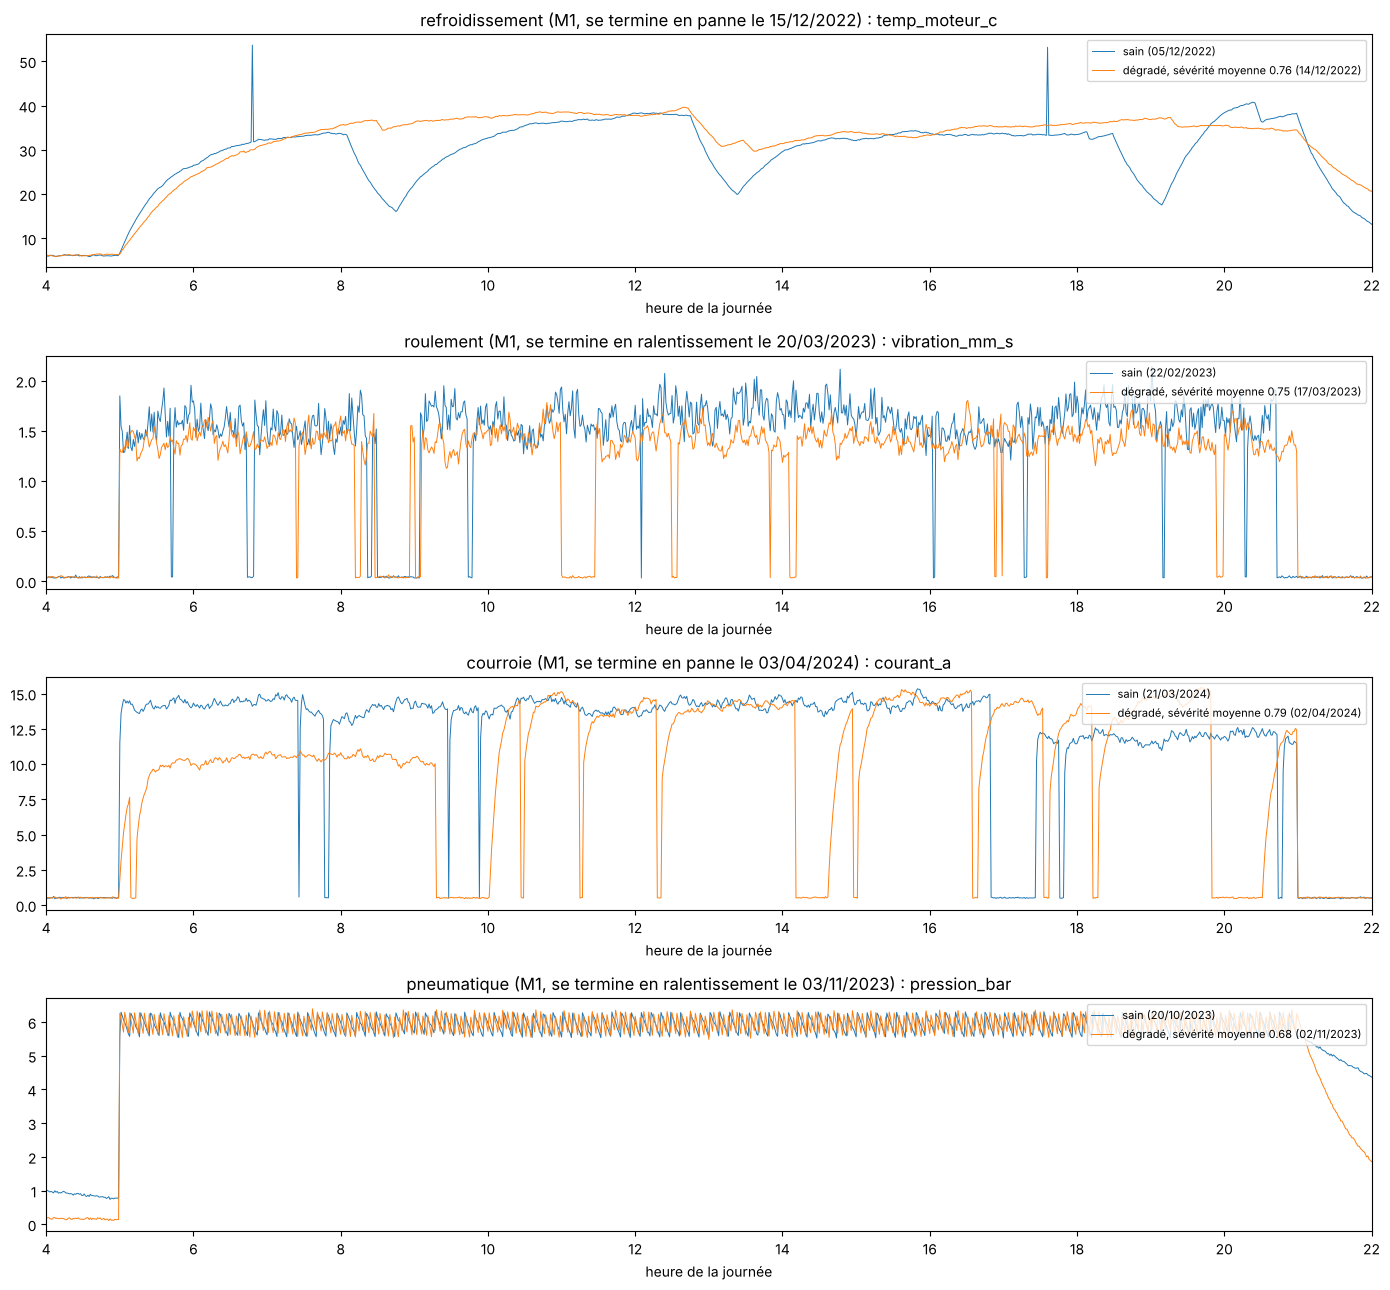

In [9]:
def jours_actifs(df):
    r = df.running.resample("D").sum()
    return r[r >= 480].index          # jours avec au moins 8 h de marche

fig, axes = plt.subplots(4, 1, figsize=(14, 13))
TYPES_EX = ["refroidissement", "roulement", "courroie", "pneumatique"]
COL_EX = {"refroidissement": "temp_moteur_c", "roulement": "vibration_mm_s", "courroie": "courant_a", "pneumatique": "pression_bar"}
for ax, ft in zip(axes, TYPES_EX):
    c = COL_EX[ft]
    for _, f in deg[(deg.type == ft) & deg.issue.ne("preventif") & (deg.precurseur_jours > 6)].iterrows():
        df = globals()[f"df_{f.machine}"].set_index("timestamp")
        jours = jours_actifs(df); sev = pd.Series(SEV[f.machine][ft], index=IDX)
        cand = [d for d in jours if f.debut_degradation <= d and d + pd.Timedelta(days=1) <= f.evenement]
        sains = [d for d in jours if d < f.debut_degradation - pd.Timedelta(days=3)]
        if cand and sains: break
    d_m = max(cand, key=lambda d: sev[d:d + pd.Timedelta(hours=23)].mean())          # jour le plus dégradé
    d_s = sains[-1]                                                                  # dernier jour sain avant la dégradation
    for d, lab in [(d_s, "sain"), (d_m, f"dégradé, sévérité moyenne {sev[d_m:d_m + pd.Timedelta(hours=23)].mean():.2f}")]:
        x = df.loc[d:d + pd.Timedelta(hours=23, minutes=59)]
        ax.plot(np.arange(len(x)) / 60, x[c].to_numpy(), lw=0.7, label=f"{lab} ({d:%d/%m/%Y})")
    ax.set_title(f"{ft} ({f.machine}, se termine en {f.issue} le {f.evenement:%d/%m/%Y}) : {c}")
    ax.set_xlabel("heure de la journée"); ax.legend(loc="upper right", fontsize=8); ax.set_xlim(4, 22)
plt.tight_layout(); plt.savefig(OUT / "controle_visuel.png", dpi=90); plt.show()

## 8. Flotte non étiquetée : 12 machines de plus (ajoutée le 15/10/2026)

Un pré-entraînement auto-supervisé ne peut payer que s'il dispose de beaucoup plus d'historique **sans étiquettes** que d'historique étiqueté. Dans une usine, c'est le cas courant : beaucoup de machines semblables enregistrent des capteurs, mais les pannes ne sont qualifiées que sur quelques-unes.

On simule donc 3 machines supplémentaires de chacun des 4 types (M5 à M16), avec les **mêmes physiques et les mêmes types de dégradations**, et des paramètres décalés de ±10 % (courant, constantes thermiques, vibration, résonance) et ±3 % (pression). Elles partagent l'atelier (mêmes canicules) mais ont leur propre planning, leurs propres dégradations et leurs propres recalibrages.

Ces machines ne servent **qu'au pré-entraînement**, sans étiquettes. Leur vérité terrain est écrite à part (`flotte_non_etiquetee/verite_terrain_flotte.csv`), pour décrire les données uniquement. Les fichiers M1 à M4 ne changent pas (graines indépendantes).

In [10]:
GENERER_FLOTTE = os.environ.get("FJEPA_FLOTTE", "1") == "1"
OUT_F = OUT / "flotte_non_etiquetee"
FLOTTE = {}
rng_f = np.random.default_rng(SEED + 500)
k = 5
for base_id, P in MACHINES.items():
    for v in range(3):
        Q = dict(P)
        for key_ in ["i0", "k_i", "tau_m", "tau_b", "v0", "s_res"]:
            Q[key_] = round(P[key_] * float(rng_f.uniform(0.9, 1.1)), 3)
        Q["p0"] = round(P["p0"] * float(rng_f.uniform(0.97, 1.03)), 3)
        Q["nom"] = f"{P['nom']} {v + 2} (flotte)"; Q["type_de"] = base_id
        FLOTTE[f"M{k}"] = Q; k += 1

if GENERER_FLOTTE:
    OUT_F.mkdir(parents=True, exist_ok=True)
    flt_faults, flt_benign = [], []
    for j, (mid, P) in enumerate(FLOTTE.items()):
        t0 = time.time()
        df, faults, benign, _ = simulate_machine(mid, P, SEED + 1000 + 10 * j)
        for y in range(4):
            a, b = pd.Timestamp(f"{2022 + y}-09-01"), pd.Timestamp(f"{2023 + y}-09-01")
            df[(df.timestamp >= a) & (df.timestamp < b)].to_csv(OUT_F / f"capteurs_{mid}_{2022 + y}-{2023 + y}.csv.gz", index=False, float_format="%g")
        for f in faults:
            flt_faults.append(dict(machine=mid, type=f["type"], issue=f["outcome"], debut_degradation=IDX[f["onset"]],
                                   evenement=IDX[f["event"]], fin_intervention=IDX[f["repair_end"]],
                                   precurseur_jours=round((f["event"] - f["onset"]) / 1440, 2)))
        flt_benign += benign
        print(f"{mid} {P['nom']:<26} {len(faults)} dégradations, marche {df.running.mean():.0%}, {time.time() - t0:.0f} s")
        del df
    pd.DataFrame(flt_faults).to_csv(OUT_F / "verite_terrain_flotte.csv", index=False)
    pd.DataFrame(flt_benign).sort_values(["machine", "debut"]).to_csv(OUT_F / "verite_terrain_benins_flotte.csv", index=False)
    json.dump(FLOTTE, open(OUT_F / "config_flotte.json", "w"), indent=2)
    print(pd.DataFrame(flt_faults).groupby(["type", "issue"]).size().unstack(fill_value=0))

M5 Mouleuse 2 (flotte)        40 dégradations, marche 39%, 50 s


M6 Mouleuse 3 (flotte)        43 dégradations, marche 38%, 51 s


M7 Mouleuse 4 (flotte)        40 dégradations, marche 39%, 51 s


M8 Démouleuse 2 (flotte)      40 dégradations, marche 39%, 52 s


M9 Démouleuse 3 (flotte)      43 dégradations, marche 39%, 54 s


...

M12 Trancheuse 3 (flotte)      43 dégradations, marche 39%, 52 s


M13 Trancheuse 4 (flotte)      39 dégradations, marche 38%, 52 s


M14 Conditionneuse 2 (flotte)  42 dégradations, marche 39%, 50 s


M15 Conditionneuse 3 (flotte)  40 dégradations, marche 39%, 50 s


M16 Conditionneuse 4 (flotte)  39 dégradations, marche 38%, 50 s
issue            panne  preventif  ralentissement
type                                             
courroie            46         18              22
electrique          60          0               0
pneumatique         64         22              30
refroidissement     60         17              35
roulement           60         21              32
